<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week06/Praktikum5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS06 - ANN (Approximate Nearest Neighbors)**<hr>
# **Praktikum 5**<hr>

In [ ]:
!pip install -q faiss-cpu annoy hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 14.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 24.8 MB/s eta 0:00:00


Annoy
  recall=0.022 | 0.0675 ms/query | 14,824 QPS
  recall=0.045 | 0.1200 ms/query | 8,333 QPS
  recall=0.077 | 0.2072 ms/query | 4,825 QPS
  recall=0.133 | 0.3999 ms/query | 2,501 QPS

Faiss
  recall=0.055 | 0.0415 ms/query | 24,076 QPS
  recall=0.191 | 0.1975 ms/query | 5,063 QPS
  recall=0.318 | 0.4116 ms/query | 2,430 QPS
  recall=0.501 | 0.8001 ms/query | 1,250 QPS

HNSW
  recall=0.299 | 0.2360 ms/query | 4,238 QPS
  recall=0.442 | 0.2769 ms/query | 3,611 QPS
  recall=0.613 | 0.5408 ms/query | 1,849 QPS
  recall=0.771 | 1.0602 ms/query | 943 QPS



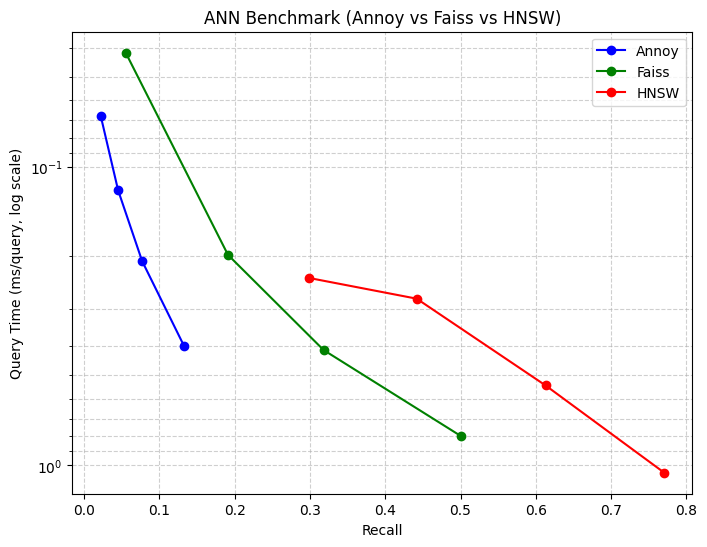

In [ ]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

for nama, hasil in results.items():
    print(nama)
    for rec, t in hasil:
        print(f"  recall={rec:.3f} | {t:.4f} ms/query | {1000/t:,.0f} QPS")
    print()

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

### **Hasil Percobaan 5: ANN Benchmark (100.000 data, 128D, k=10)**

| Metode | Parameter | Recall | Query time (ms/query) | QPS |
|---|---|---|---|---|
| Annoy (10 tree) | search_k = 200 | 0.022 | 0.0675 | 14,824 |
| Annoy (10 tree) | search_k = 500 | 0.045 | 0.1200 | 8,333 |
| Annoy (10 tree) | search_k = 1000 | 0.077 | 0.2072 | 4,825 |
| Annoy (10 tree) | search_k = 2000 | 0.133 | 0.3999 | 2,501 |
| FAISS IVF | nprobe = 1 | 0.055 | 0.0415 | 24,076 |
| FAISS IVF | nprobe = 5 | 0.191 | 0.1975 | 5,063 |
| FAISS IVF | nprobe = 10 | 0.318 | 0.4116 | 2,430 |
| FAISS IVF | nprobe = 20 | 0.501 | 0.8001 | 1,250 |
| HNSW | ef = 50 | 0.299 | 0.2360 | 4,238 |
| HNSW | ef = 100 | 0.442 | 0.2769 | 3,611 |
| HNSW | ef = 200 | 0.613 | 0.5408 | 1,849 |
| HNSW | ef = 400 | 0.771 | 1.0602 | 943 |

**Analisis:**

1. **Trade-off recall vs kecepatan.** Pada ketiga metode, menaikkan parameter pencarian (`search_k`, `nprobe`, `ef`) menaikkan recall tetapi memperlambat query. Contohnya HNSW naik dari recall 0.299 ke 0.771 sementara QPS turun dari 4.238 ke 943.
2. **HNSW memberi trade-off terbaik.** Garis HNSW berada paling kanan, artinya mencapai recall tertinggi (0.771), jauh di atas FAISS (0.501) dan Annoy (0.133). Pada recall yang hampir sama, HNSW juga lebih cepat dari FAISS (recall 0.299 dalam 0.236 ms, dibanding recall 0.318 dalam 0.412 ms).
3. **FAISS IVF di posisi tengah.** FAISS mengungguli Annoy: pada nprobe = 5 recall-nya 0.191 dengan 0.1975 ms, sedangkan Annoy hanya mencapai recall 0.133 dengan 0.3999 ms. FAISS juga yang tercepat pada pengaturan paling kasar (nprobe = 1, 24.076 QPS), tetapi dengan recall rendah (0.055).
4. **Annoy paling rendah recall-nya** pada rentang parameter yang diuji (maksimum 0.133), sehingga untuk data ini perlu lebih banyak tree dan `search_k` lebih besar agar akurat.
5. **Recall keseluruhan relatif rendah** karena datasetnya acak seragam berdimensi tinggi (128D). Pada data seperti ini jarak antar titik hampir seragam dan tidak ada struktur kelompok yang bisa dimanfaatkan, sehingga pencarian aproksimasi paling sulit. Pada data nyata (misalnya embedding), recall pada kecepatan yang sama umumnya jauh lebih tinggi.